# 02 - Feature Engineering

**Goal:** show how the customer-level feature table is built and check that it is **leakage-safe**.

**Idea:** pick a *cutoff date*. Every feature describes the customer using only purchases **before** the cutoff. The label (churn) and the revenue target look **after** the cutoff:

```
 ---------- history (features) ---------- | cutoff | --- 90 days (labels) ---
```

* `churn = 1` when the customer makes no purchase in the 90 days after the cutoff.
* `future_revenue` is the sales revenue in those 90 days (the CLV target).

Built by `python -m src.features.build_features`.

In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Work from the project root no matter where Jupyter was started.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.utils.config import get_config_value, resolve_path

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
print("Project folder:", ROOT)

Project folder: e:\customer-behavior-prediction


## 1. Load the feature table

In [2]:
features = pd.read_parquet(resolve_path(get_config_value("paths.customer_features", "data/processed/customer_features.parquet")))
cutoff = pd.Timestamp(get_config_value("features.cutoff_date", "2011-09-09"))
horizon = int(get_config_value("features.churn_horizon_days", 90))

print(f"{len(features):,} customers x {features.shape[1]} columns")
print(f"Cutoff date: {cutoff:%d %b %Y} | label window: {horizon} days after the cutoff")
display(features.head())

5,262 customers x 34 columns
Cutoff date: 09 Sep 2011 | label window: 90 days after the cutoff


,customer_id,frequency,monetary_total,monetary_avg,avg_basket_size,avg_basket_lines,recency_days,tenure_days,interpurchase_mean_days,interpurchase_std_days,purchase_frequency_trend,seasonal_order_share,n_returns,return_rate,historical_clv,discount_line_share,avg_price_index,engagement_score,affinity_seasonal_christmas,affinity_candles_lighting,affinity_jewellery_accessories,affinity_toys_games,affinity_garden_outdoor,affinity_kitchen_dining,affinity_stationery_party,affinity_bags_storage,affinity_home_decor,affinity_other,top_category,n_categories,category_entropy,churn,future_revenue,next_category
0,12346,12,"77,556.460","6,463.038","6,190.417",2.833,233.583,633.643,36.369,65.515,-0.010,0.417,3,0.997,264.860,0.029,0.983,76.815,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.995,0.002,0.003,Bags & Storage,6,0.015,1,0.000,NaN
1,12347,6,"3,402.390",567.065,349.833,27.333,37.633,312.403,54.954,12.905,-0.014,0.333,0,0.000,"3,402.390",0.037,0.992,79.406,0.000,0.096,0.000,0.032,0.013,0.231,0.127,0.184,0.147,0.169,Kitchen & Dining,8,0.820,0,"1,519.140",Kitchen & Dining
2,12348,4,"1,388.400",347.100,622.000,10.000,156.551,346.376,63.275,21.084,-0.063,0.250,0,0.000,"1,388.400",0.091,0.979,59.559,0.068,0.000,0.000,0.038,0.000,0.204,0.328,0.000,0.070,0.292,Stationery & Party,6,0.670,0,270.000,Other
3,12349,2,"2,221.140","1,110.570",495.500,50.000,315.651,497.444,181.794,0.000,-0.031,0.500,1,0.011,"2,196.990",0.040,0.994,47.498,0.000,0.000,0.000,0.008,0.026,0.233,0.071,0.173,0.358,0.131,Home Decor,7,0.694,0,"1,457.550",Kitchen & Dining
4,12350,1,294.400,294.400,196.000,16.000,218.333,218.333,0.000,0.000,-0.010,0.000,0,0.000,294.400,0.000,1.000,26.736,0.000,0.000,0.000,0.067,0.000,0.133,0.102,0.118,0.230,0.350,Other,6,0.712,1,0.000,NaN


## 2. Feature groups

In [3]:
targets = ["churn", "future_revenue", "next_category"]
identifier = ["customer_id"]
numeric = features.select_dtypes("number").columns.difference(targets + identifier)
text = features.select_dtypes(exclude="number").columns.difference(targets)

print(f"{len(numeric)} numeric model inputs:")
print(", ".join(numeric))
print(f"\nNon-numeric columns (not used as model inputs): {list(text)}")

29 numeric model inputs:
affinity_bags_storage, affinity_candles_lighting, affinity_garden_outdoor, affinity_home_decor, affinity_jewellery_accessories, affinity_kitchen_dining, affinity_other, affinity_seasonal_christmas, affinity_stationery_party, affinity_toys_games, avg_basket_lines, avg_basket_size, avg_price_index, category_entropy, discount_line_share, engagement_score, frequency, historical_clv, interpurchase_mean_days, interpurchase_std_days, monetary_avg, monetary_total, n_categories, n_returns, purchase_frequency_trend, recency_days, return_rate, seasonal_order_share, tenure_days

Non-numeric columns (not used as model inputs): ['top_category']


## 3. The two targets

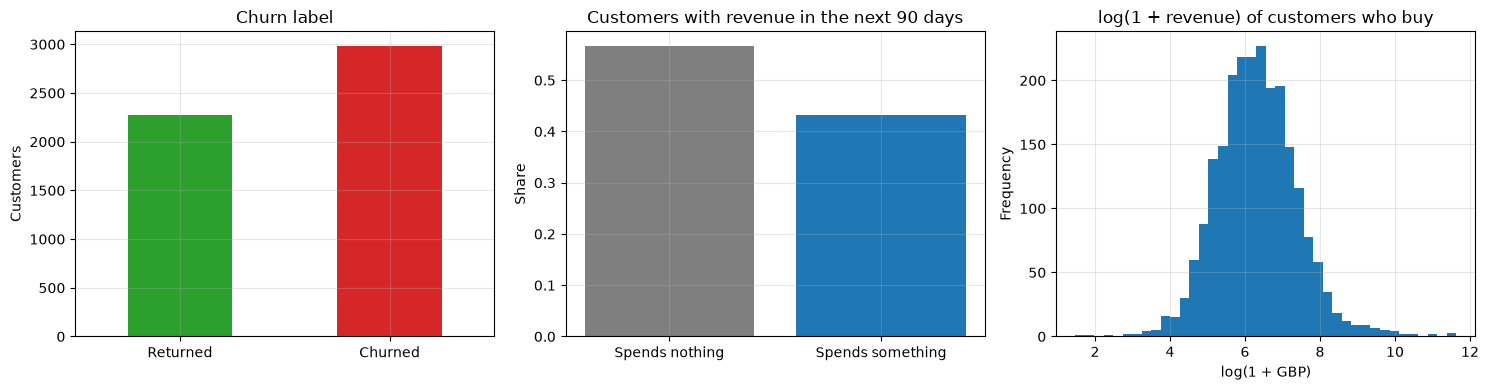

Churn rate: 56.7%
Customers with zero future revenue: 56.7%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

features["churn"].value_counts().sort_index().rename({0: "Returned", 1: "Churned"}).plot.bar(ax=axes[0], color=["tab:green", "tab:red"], rot=0)
axes[0].set(title="Churn label", xlabel="", ylabel="Customers")

zero = (features["future_revenue"] == 0).mean()
axes[1].bar(["Spends nothing", "Spends something"], [zero, 1 - zero], color=["tab:gray", "tab:blue"])
axes[1].set(title="Customers with revenue in the next 90 days", ylabel="Share")

np.log1p(features.loc[features["future_revenue"] > 0, "future_revenue"]).plot.hist(bins=40, ax=axes[2], color="tab:blue")
axes[2].set(title="log(1 + revenue) of customers who buy", xlabel="log(1 + GBP)")
plt.tight_layout()
plt.show()

print(f"Churn rate: {features['churn'].mean():.1%}")
print(f"Customers with zero future revenue: {zero:.1%}")

About half of the customers spend **nothing** in the label window, and the rest range from a few pounds to thousands. A log transform makes the revenue target usable for regression.

## 4. Recency, frequency and spend (RFM)

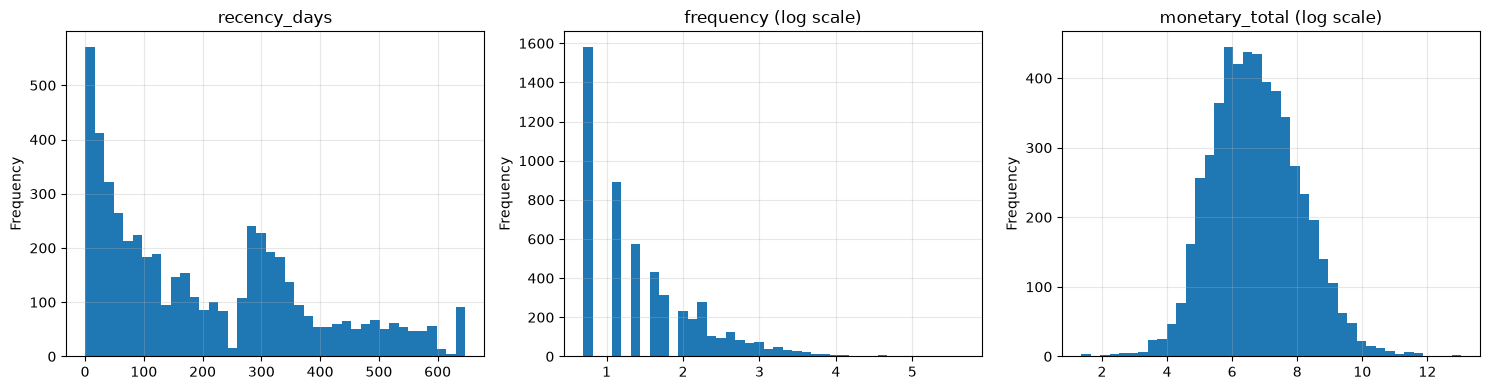

,recency_days,frequency,monetary_total
churn,,,
returned,65.608,5.000,"1,598.745"
churned,284.439,2.000,478.705


In [5]:
rfm = [c for c in ["recency_days", "frequency", "monetary_total"] if c in features.columns]
fig, axes = plt.subplots(1, len(rfm), figsize=(5 * len(rfm), 4))
axes = np.atleast_1d(axes)
for ax, column in zip(axes, rfm):
    values = features[column]
    (np.log1p(values.clip(lower=0)) if values.skew() > 1 else values).plot.hist(bins=40, ax=ax, color="tab:blue")
    ax.set(title=column + (" (log scale)" if values.skew() > 1 else ""), xlabel="")
plt.tight_layout()
plt.show()

display(features.groupby("churn")[rfm].median().rename(index={0: "returned", 1: "churned"}))

Churned customers last bought **longer ago**, bought **less often** and spent **less**. These are the strongest signals the models learn.

## 5. Skewed features

In [6]:
skew = features[numeric].skew().sort_values(ascending=False)
display(skew.head(10).to_frame("skewness"))
print(f"{(skew.abs() > 1).sum()} of {len(skew)} numeric features have |skewness| > 1.")
print("Linear and neural models therefore apply a signed log transform to these columns (SignedLog1p) before scaling; tree models use the raw values.")

,skewness
avg_price_index,71.487
avg_basket_size,51.007
historical_clv,24.817
monetary_total,23.986
monetary_avg,14.101
frequency,10.560
n_returns,9.613
affinity_jewellery_accessories,8.427
return_rate,7.946
affinity_garden_outdoor,6.571


25 of 29 numeric features have |skewness| > 1.
Linear and neural models therefore apply a signed log transform to these columns (SignedLog1p) before scaling; tree models use the raw values.


## 6. Which features move with churn?

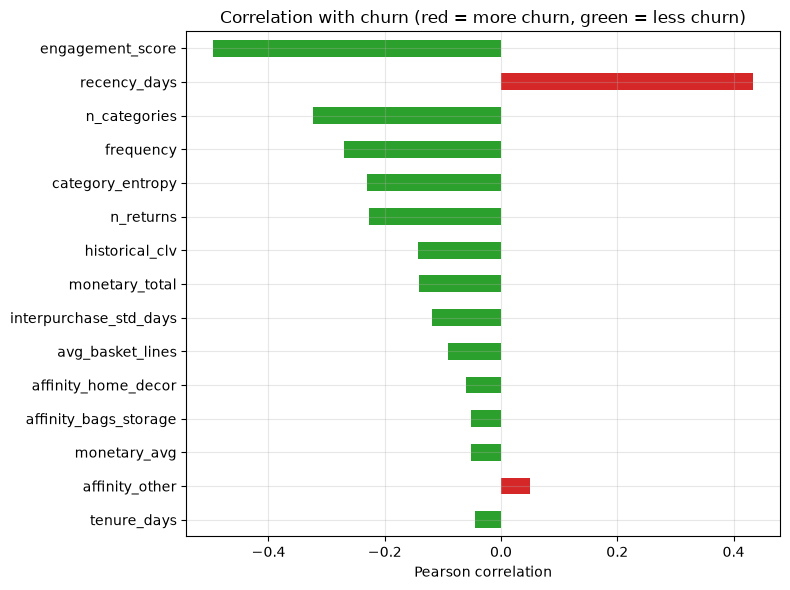

In [7]:
correlation = features[numeric].corrwith(features["churn"]).dropna()
top = correlation.reindex(correlation.abs().sort_values(ascending=False).head(15).index)[::-1]

top.plot.barh(color=["tab:red" if value > 0 else "tab:green" for value in top], figsize=(8, 6))
plt.title("Correlation with churn (red = more churn, green = less churn)")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

## 7. Leakage checks

Two spot checks against the cleaned transactions. Every number here must be computed **only** from data before the cutoff, and the label must agree with what happens after it.

In [8]:
tx = pd.read_parquet(resolve_path(get_config_value("paths.interim_transactions", "data/interim/transactions_clean.parquet")))
sales = tx[~tx["is_cancellation"]]

# Check 1: recency is measured at the cutoff, from the last purchase before it.
sample_ids = features["customer_id"].sample(5, random_state=1)
rows = []
for customer in sample_ids:
    before = sales[(sales["customer_id"] == customer) & (sales["invoice_date"] < cutoff)]
    recomputed = (cutoff - before["invoice_date"].max()).days if len(before) else np.nan
    stored = features.loc[features["customer_id"] == customer, "recency_days"].iloc[0]
    rows.append({"customer_id": customer, "recency_in_table": stored, "recomputed_from_transactions": recomputed})
display(pd.DataFrame(rows))

# Check 2: nobody who bought in the label window is labelled as churned.
window = sales[(sales["invoice_date"] >= cutoff) & (sales["invoice_date"] < cutoff + pd.Timedelta(days=horizon))]
buyers = set(window["customer_id"])
churn_among_buyers = features.loc[features["customer_id"].isin(buyers), "churn"].mean()
print(f"Customers who bought during the label window: {len(buyers):,}")
print(f"Share of them labelled as churned (should be about 0%): {churn_among_buyers:.2%}")

# Check 3: the table must not contain purchases made after the cutoff.
print(f"Latest purchase used for features must be before the cutoff: {cutoff:%Y-%m-%d}")

,customer_id,recency_in_table,recomputed_from_transactions
0,13164,477.422,477
1,14628,150.387,150
2,15672,633.297,633
3,16859,52.487,52
4,17225,489.515,489


Customers who bought during the label window: 2,873
Share of them labelled as churned (should be about 0%): 0.00%
Latest purchase used for features must be before the cutoff: 2011-09-09


## 8. Summary

| Step | Decision |
|---|---|
| Cutoff | 9 Sep 2011 - leaves a full 90-day label window inside the data |
| Labels | `churn` and `future_revenue` computed only from the 90 days after the cutoff |
| Features | RFM, basket, timing, return and discount behaviour, trend, category affinity - all from before the cutoff |
| Skew | log transform for linear/neural models, raw values for trees |
| Split | one stratified 70 / 15 / 15 split shared by every model |

Next: `03_model_experiments.ipynb`.